# Process, outcome, and the two handcoded programs

One architecture. Four parameter settings.

- **process** and **outcome** start from the same random initialization and are trained on the trace and on the final answer.
- **handcoded process** and **handcoded outcome** are the exact programs already written into those tensors. They are not trained. Their loss and accuracy are flat reference lines.

The task is counting: `s_t = (s_{t-1} + [w_t = q]) mod 2`, block layout, horizon 8. Functions come from `lettertrace.py`. GPU 3 is selected below; 

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "3"

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import HTML, Image, display
from matplotlib.animation import FuncAnimation, PillowWriter

ROOT = Path.cwd() if (Path.cwd() / "handcoded").is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import handcoded.lettertrace as lt

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"], "mathtext.fontset": "dejavusans",
    "axes.titlesize": 14, "axes.labelsize": 12, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.facecolor": "#EAEAF2", "axes.edgecolor": "#EAEAF2", "axes.grid": True,
    "grid.color": "white", "grid.linewidth": 1.2, "legend.framealpha": 0.82,
    "legend.facecolor": "#ECECF2", "legend.edgecolor": "#C8C8C8",
})

lt.configure(
    task="count", layout="block", alphabet=4, word_len=16, mod=3,
    rho=1.0, n_blocks=2, train_size=20_000, test_size=2000,
    steps=20_000, batch_size=128, lr=1e-3, init_std=0.04, seed=42,
    eval_every=100, save_every=0, device="cuda" if torch.cuda.is_available() else "cpu",
)
print(f"device={lt.device}  n={lt.n}  m={lt.mod}  steps={lt.steps}  width={lt.W}")

device=cuda  n=16  m=3  steps=20000  width=61


/home/hariguru/aayus/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Build one corpus and one initialization. Score the handcoded programs before any gradient step.

In [2]:
train, shown, test = lt.make_corpus()
theta_0 = lt.init_theta()
hand = lt.handcoded_params()
probe = test[0]

hand_stats = {}
for mode, params in hand.items():
    exact, answer, steps_ok = lt.free_run(params, test, mode)
    loss = lt.mean_loss(params, mode, train, shown)
    hand_stats[mode] = dict(exact=exact, answer=answer, steps_ok=steps_ok, loss=loss)
    print(f"handcoded {mode:8s}  loss {loss:.4f}  exact {exact:.3f}  answer {answer:.3f}")

corpus  train=20000  clean=20000/20000 (1.000)  test=2000  (streams: train seed, corrupt seed+10000, test seed+20000)
handcoded process   loss 0.0000  exact 1.000  answer 1.000
handcoded outcome   loss 0.0000  exact 1.000  answer 1.000


Train the two learned models. `keep_state` stores the weights at each evaluation so the replay can decode a held-out word.

In [3]:
learned = {}
for mode in ("process", "outcome"):
    params, history = lt.train_mode(mode, theta_0, train, shown, test, keep_state=True)
    learned[mode] = dict(params=params, history=history)

process:   0%|          | 1/20000 [00:00<1:11:51,  4.64it/s, loss=2.297]

process:   1%|          | 128/20000 [00:00<02:09, 153.45it/s, loss=0.529]

process  step   100  loss 0.6482  test exact 0.005  answer 0.313  step acc 0.330


process:   1%|          | 218/20000 [00:01<02:05, 157.86it/s, loss=0.474]             

process  step   200  loss 0.4906  test exact 0.006  answer 0.329  step acc 0.385


process:   2%|▏         | 328/20000 [00:02<02:02, 160.23it/s, loss=0.483]

... (791 outputs left out)

outcome: 100%|█████████▉| 19933/20000 [01:57<00:00, 184.91it/s, loss=0.301]

outcome  step 19900  loss 0.2881  test exact 0.352  answer 0.352


outcome: 100%|██████████| 20000/20000 [01:58<00:00, 169.34it/s, loss=0.277, exact=0.341]

outcome  step 20000  loss 0.2770  test exact 0.341  answer 0.341


Replay. Top row: batch loss, exact continuation, and answer accuracy. Solid curves are the trained models (faint line: batch loss, thick line: trailing mean). Dashed lines are the handcoded programs. The bottom row is one held-out word: green means the greedy continuation matches the gold trace.


Animation size has reached 21029223 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


wrote /home/hariguru/aayus/trace/handcoded/animations/lettertrace_train.gif
wrote /home/hariguru/aayus/trace/handcoded/animations/lettertrace_train.mp4
wrote /home/hariguru/aayus/trace/handcoded/animations/lettertrace_train.png
wrote /home/hariguru/aayus/trace/handcoded/animations/lettertrace_train.pdf
wrote /home/hariguru/aayus/trace/handcoded/animations/lettertrace_curves.png
wrote /home/hariguru/aayus/trace/handcoded/animations/lettertrace_curves.pdf


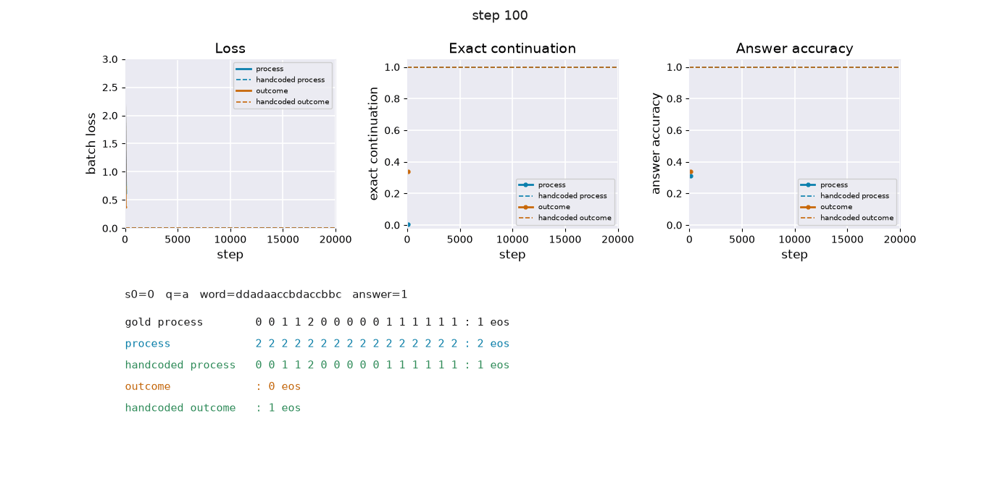

In [4]:
PROCESS, OUTCOME, INK, OK = "#0a7fad", "#c8680a", "#1a1a1a", "#2e8b57"
COLOR = {"process": PROCESS, "outcome": OUTCOME}

def token_name(tid):
    if tid < lt.A:
        return "abcd"[tid]
    if tid < lt.A + lt.V:
        return str(tid - lt.A)
    if tid == lt.COLON:
        return ":"
    if tid == lt.EOS:
        return "eos"
    return "?"

def gold_tokens(example, mode):
    states = example[3]
    tail = [lt.COLON, lt.A + states[-1], lt.EOS]
    if mode == "outcome":
        return tail
    return [lt.A + s for s in states] + tail

def continuation(params, example, mode):
    rows, _ = lt.generate(params, [example], mode)
    return rows[0]

def on_device(snapshot):
    return {k: v.to(lt.device) for k, v in snapshot.items()}

def rolling(values, window=25):
    out = np.cumsum(values, dtype=float)
    out[window:] = out[window:] - out[:-window]
    counts = np.minimum(np.arange(1, len(values) + 1), window)
    return out / counts

frames = [r for r in learned["process"]["history"] if "params" in r]
by_step = {
    mode: {r["step"]: r for r in learned[mode]["history"] if "params" in r}
    for mode in ("process", "outcome")
}
hand_text = {
    mode: " ".join(token_name(t) for t in continuation(hand[mode], probe, mode))
    for mode in ("process", "outcome")
}
gold_text = {
    mode: " ".join(token_name(t) for t in gold_tokens(probe, mode))
    for mode in ("process", "outcome")
}
s0, q, word, states = probe
prompt_line = f"s0={s0}   q={'abcd'[q]}   word={''.join('abcd'[c] for c in word)}   answer={states[-1]}"

fig = plt.figure(figsize=(13.8, 6.8))
grid = fig.add_gridspec(2, 3, height_ratios=[1.2, 0.95], hspace=0.5, wspace=0.34)
ax_loss = fig.add_subplot(grid[0, 0])
ax_exact = fig.add_subplot(grid[0, 1])
ax_answer = fig.add_subplot(grid[0, 2])
ax_trace = fig.add_subplot(grid[1, :])

def plot_score(ax, seen, key):
    for mode in ("process", "outcome"):
        ev = [r for r in seen[mode] if key in r]
        ax.plot([r["step"] for r in ev], [r[key] for r in ev],
                color=COLOR[mode], lw=2.0, marker="o", ms=3.5, label=mode)
        ax.axhline(hand_stats[mode][key], color=COLOR[mode], ls="--", lw=1.2,
                   label=f"handcoded {mode}")
    ax.set_xlim(0, lt.steps)
    ax.set_ylim(-0.02, 1.05)
    ax.set_xlabel("step")
    ax.legend(fontsize=7, loc="lower right")

def draw(i):
    step = frames[i]["step"]
    ax_loss.clear()
    ax_exact.clear()
    ax_answer.clear()
    ax_trace.clear()
    seen = {}
    for mode in ("process", "outcome"):
        hist = learned[mode]["history"]
        seen[mode] = [r for r in hist if r["step"] <= step]
        xs = [r["step"] for r in seen[mode]]
        ys = [r["loss"] for r in seen[mode]]
        ax_loss.plot(xs, ys, color=COLOR[mode], alpha=0.25, lw=1)
        ax_loss.plot(xs, rolling(ys), color=COLOR[mode], lw=2.0, label=mode)
        ax_loss.axhline(hand_stats[mode]["loss"], color=COLOR[mode], ls="--", lw=1.2,
                        label=f"handcoded {mode}")
    ax_loss.set_xlim(0, lt.steps)
    ax_loss.set_ylim(0, 3)
    ax_loss.set_xlabel("step")
    ax_loss.set_ylabel("batch loss")
    ax_loss.set_title("Loss")
    ax_loss.legend(fontsize=7, loc="upper right")
    plot_score(ax_exact, seen, "exact")
    ax_exact.set_ylabel("exact continuation")
    ax_exact.set_title("Exact continuation")
    plot_score(ax_answer, seen, "answer")
    ax_answer.set_ylabel("answer accuracy")
    ax_answer.set_title("Answer accuracy")

    ax_trace.set_axis_off()
    ax_trace.set_title(prompt_line, loc="left", fontsize=11, color=INK)
    lines = [("gold process", gold_text["process"], INK)]
    for mode in ("process", "outcome"):
        pred = continuation(on_device(by_step[mode][step]["params"]), probe, mode)
        text = " ".join(token_name(t) for t in pred)
        match = pred == gold_tokens(probe, mode)
        lines.append((mode, text, OK if match else COLOR[mode]))
        lines.append((f"handcoded {mode}", hand_text[mode], OK))
    for row, (label, text, color) in enumerate(lines):
        y = 0.86 - row * 0.16
        ax_trace.text(0.0, y, f"{label:18s}  {text}", color=color, fontsize=11,
                      fontfamily="monospace", transform=ax_trace.transAxes, va="center")
    fig.suptitle(f"step {step}", fontsize=13, color=INK)

anim = FuncAnimation(fig, draw, frames=len(frames), interval=180)
out_dir = ROOT / "handcoded" / "animations"
out_dir.mkdir(parents=True, exist_ok=True)
gif_path = out_dir / "lettertrace_train.gif"
anim.save(gif_path, writer=PillowWriter(fps=6))
mp4_path = out_dir / "lettertrace_train.mp4"
try:
    anim.save(mp4_path, writer="ffmpeg", fps=6)
except Exception as err:
    mp4_path = None
    print(f"mp4 skipped ({err})")

draw(len(frames) - 1)
for ext in ("png", "pdf"):
    fig.savefig(out_dir / f"lettertrace_train.{ext}", dpi=160, bbox_inches="tight")

cfig, axes = plt.subplots(1, 3, figsize=(13.8, 3.5))
full = {}
for mode in ("process", "outcome"):
    hist = learned[mode]["history"]
    full[mode] = hist
    xs = [r["step"] for r in hist]
    ys = [r["loss"] for r in hist]
    axes[0].plot(xs, ys, color=COLOR[mode], alpha=0.25, lw=1)
    axes[0].plot(xs, rolling(ys), color=COLOR[mode], lw=2.0, label=mode)
    axes[0].axhline(hand_stats[mode]["loss"], color=COLOR[mode], ls="--", lw=1.2,
                    label=f"handcoded {mode}")
plot_score(axes[1], full, "exact")
plot_score(axes[2], full, "answer")
axes[0].set_xlim(0, lt.steps)
axes[0].set_ylim(0, 3)
axes[0].set_xlabel("step")
axes[0].set_ylabel("batch loss")
axes[0].set_title("Loss")
axes[0].legend(fontsize=7, loc="upper right")
axes[1].set_ylabel("exact continuation")
axes[1].set_title("Exact continuation")
axes[2].set_ylabel("answer accuracy")
axes[2].set_title("Answer accuracy")
cfig.tight_layout()
for ext in ("png", "pdf"):
    cfig.savefig(out_dir / f"lettertrace_curves.{ext}", dpi=160, bbox_inches="tight")
plt.close(cfig)

html = anim.to_jshtml()
plt.close(fig)
saved = [gif_path, out_dir / "lettertrace_train.png", out_dir / "lettertrace_train.pdf",
        out_dir / "lettertrace_curves.png", out_dir / "lettertrace_curves.pdf"]
if mp4_path is not None:
    saved.insert(1, mp4_path)
print("\n".join(f"wrote {path}" for path in saved))
display(Image(filename=str(gif_path)))
display(HTML(html))


In [5]:
# Step-by-step greedy decoding of one held-out prompt by the two handcoded programs.
# Each line is one generated token: the position that predicts it, the registers the
# program reads at that position (residual stream after the last block), the top-3
# logits, and the chosen token against the gold one. Change EXAMPLE to try another prompt.
import math
import torch
from torch.nn import functional as F

EXAMPLE = 0                      # index into the held-out test set
ex = test[EXAMPLE]
s0, q, word, states = ex
letter = lambda c: chr(ord("a") + c)

def name(tid):
    if tid < lt.A:
        return letter(tid)
    if tid < lt.A + lt.V:
        return str(tid - lt.A)
    return {lt.SEP: "SEP", lt.COLON: ":", lt.EOS: "EOS"}.get(tid, "?")

@torch.no_grad()
def residuals(params, ids):
    """lt.forward, keeping the residual stream after every block."""
    T = ids.shape[1]
    x = params["wte"][ids] + params["wpe"][:T]
    future = torch.ones(T, T, dtype=torch.bool, device=ids.device).triu(1)
    per_block = []
    for b in range(lt.n_blocks):
        qh = torch.einsum("btw,hdw->bhtd", x, params[f"{b}.q"])
        kh = torch.einsum("btw,hdw->bhtd", x, params[f"{b}.k"])
        vh = torch.einsum("btw,hvw->bhtv", x, params[f"{b}.v"])
        att = (qh @ kh.transpose(-1, -2) / math.sqrt(lt.P)).masked_fill(future, -math.inf)
        x = x + (att.softmax(-1) @ vh).sum(1)
        x = x + F.relu(x @ params[f"{b}.mlp_in"].T + params[f"{b}.mlp_b"]) @ params[f"{b}.mlp_out"].T
        per_block.append(x[0])
    return x[0] @ params["readout"].T, per_block

def onehot(vec):
    i = int(vec.argmax())
    return f"{i}({float(vec[i]):.2f})"

def registers(x, mode):
    if mode == "process":    # previous state, current match bit, looked-up next state
        return f"prev={onehot(x[lt.PREV])} mt={float(x[lt.MT][0]):.2f} out={onehot(x[lt.OUT])}"
    return f"cnt={float(x[lt.CNT][0]):6.2f} s0={onehot(x[lt.S0])} out={onehot(x[lt.OUT])}"   # count, start, answer

gold_bits = [int(c == q) for c in word]
print(f"prompt: s0={s0}  q={letter(q)}  word={''.join(letter(c) for c in word)}  "
      f"(n={lt.n}, K={lt.mod})")
print(f"gold match bits b_t: {''.join(map(str, gold_bits))}   gold states s_1..s_n: "
      f"{' '.join(map(str, states))}   answer s_n={states[-1]}\n")

# for mode in ("process", "outcome"):
#     params = hand[mode]
#     gold = ([lt.A + s for s in states] if mode == "process" else []) + [lt.COLON, lt.A + states[-1], lt.EOS]
#     ids = torch.tensor([lt.prompt(ex)], device=lt.device)
#     print(f"=== handcoded {mode} ===")
#     _, blocks = residuals(params, ids)
#     bits = [float(blocks[0][1 + t][lt.MATCH][0]) for t in range(1, lt.n + 1)]
#     print("block-1 match bits at the letters: " + " ".join(f"{b:.2f}" for b in bits))
#     print(f"{'pos':>4} {'predicts':>9}  {'registers after block 2':42s} {'top-3 logits':34s} {'gen':>4} {'gold':>4}")
#     for k, g in enumerate(gold):
#         logits, blocks = residuals(params, ids)
#         pos = ids.shape[1] - 1
#         top = logits[pos].topk(3)
#         top_txt = "  ".join(f"{name(int(i))}:{float(v):6.1f}" for v, i in zip(top.values, top.indices))
#         tok = int(logits[pos].argmax())
#         what = f"s_{k + 1}" if mode == "process" and k < lt.n else ["':'", "answer", "EOS"][k - (lt.n if mode == "process" else 0)]
#         mark = "ok" if tok == g else "WRONG"
#         print(f"{pos:4d} {what:>9}  {registers(blocks[-1][pos], mode):42s} {top_txt:34s} {name(tok):>4} {name(g):>4}  {mark}")
#         ids = torch.cat([ids, torch.tensor([[tok]], device=lt.device)], 1)
#     out = ids[0, lt.n + 3:].tolist()
#     print(f"continuation: {' '.join(name(t) for t in out)}   exact={out == gold}\n")


prompt: s0=0  q=a  word=ddadaaccbdaccbbc  (n=16, K=3)
gold match bits b_t: 0010110000100000   gold states s_1..s_n: 0 0 1 1 2 0 0 0 0 0 1 1 1 1 1 1   answer s_n=1

